# Speech command classification

This experiment uses local Speech Commands WAV files in `speech_commands/<class>/`. The dataset and pretrained model weights are not included. Training, validation and test partitions are disjoint at the file level. The local filenames do not preserve speaker identifiers, so the split cannot guarantee separation by speaker; scores can overestimate performance on new speakers. The saved results were generated on Kaggle with the corrected split and evaluated on the held-out test files.

**Data:** A local seven-class speech-command WAV collection under `speech_commands/<class>/`. The exact original public source is not confirmed. A private copy of the files used for the saved experiments is attached to the author’s Kaggle runs; other readers need to provide their own compatible files.

In [1]:
import os
import torch
import torchaudio
import soundfile as sf
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tqdm.auto import tqdm
from transformers import (
    AutoFeatureExtractor,
    Wav2Vec2ForSequenceClassification,
    HubertForSequenceClassification
)

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
SAMPLE_RATE = 16000
BATCH_SIZE = 8
EPOCHS = 10

CLASSES = ['down', 'left', 'off', 'on', 'right', 'stop', 'up']
NUM_CLASSES = len(CLASSES)

In [2]:
MODEL_NAME = "superb/wav2vec2-base-superb-ks"
feature_extractor = AutoFeatureExtractor.from_pretrained(MODEL_NAME)


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

In [3]:
class SpeechCommandsDataset(Dataset):
    def __init__(self, root_dir, classes):
        self.files = []
        self.labels = []
        self.classes = classes

        for label, cls in enumerate(classes):
            cls_dir = os.path.join(root_dir, cls)
            for fname in sorted(os.listdir(cls_dir)):
                if fname.endswith(".wav"):
                    self.files.append(os.path.join(cls_dir, fname))
                    self.labels.append(label)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        wav_np, sr = sf.read(self.files[idx], dtype="float32")
        waveform = torch.from_numpy(wav_np)

        if waveform.ndim == 1:
            pass
        else:
            waveform = waveform.mean(dim=1)

        if sr != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(waveform, sr, SAMPLE_RATE)

        # Fixed length (1 sec) so DataLoader can stack tensors into a batch.
        target_len = SAMPLE_RATE
        if waveform.shape[0] < target_len:
            waveform = torch.nn.functional.pad(waveform, (0, target_len - waveform.shape[0]))
        else:
            waveform = waveform[:target_len]

        inputs = feature_extractor(
            waveform,
            sampling_rate=SAMPLE_RATE,
            return_tensors="pt",
            padding=True,
            return_attention_mask=True
        )

        input_values = inputs["input_values"].squeeze(0)
        attention_mask = inputs.get("attention_mask")
        if attention_mask is None:
            attention_mask = torch.ones_like(input_values, dtype=torch.long)
        else:
            attention_mask = attention_mask.squeeze(0)

        return {
            "input_values": input_values,
            "attention_mask": attention_mask,
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [4]:
DATA_ROOT = os.environ.get("SPEECH_COMMANDS_ROOT", "speech_commands")
dataset = SpeechCommandsDataset(DATA_ROOT, CLASSES)
indices = np.arange(len(dataset))
labels = np.asarray(dataset.labels)
train_val_idx, test_idx = train_test_split(indices, test_size=0.15, random_state=42, stratify=labels)
train_idx, val_idx = train_test_split(train_val_idx, test_size=0.1765, random_state=42,
                                      stratify=labels[train_val_idx])
train_ds = torch.utils.data.Subset(dataset, train_idx)
val_ds = torch.utils.data.Subset(dataset, val_idx)
test_ds = torch.utils.data.Subset(dataset, test_idx)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train: {len(train_ds)}, validation: {len(val_ds)}, test: {len(test_ds)}")

Train: 11529, validation: 2471, test: 2471


In [5]:
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    use_weighted_layer_sum=False,  # Use the final layer; compatible with Transformers 5.x.
    ignore_mismatched_sizes=True
)

model.to(DEVICE)

def get_backbone(m):
    if hasattr(m, "wav2vec2"):
        return m.wav2vec2
    if hasattr(m, "hubert"):
        return m.hubert
    raise ValueError("Model backbone is neither wav2vec2 nor hubert")

backbone = get_backbone(model)

for p in model.parameters():
    p.requires_grad = False

for p in model.classifier.parameters():
    p.requires_grad = True

if hasattr(model, "projector"):
    for p in model.projector.parameters():
        p.requires_grad = True

UNFREEZE_EPOCH = 2
N_UNFREEZE_LAYERS = 3
HEAD_LR = 3e-4
FT_LR = 5e-5
WEIGHT_DECAY = 1e-4

def build_optimizer(lr):
    return torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )

optimizer = build_optimizer(HEAD_LR)


config.json:   0%|          | 0.00/2.42k [00:00<?, ?B/s]

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `12`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/215 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: superb/wav2vec2-base-superb-ks
Key               | Status     |                                                                                        
------------------+------------+----------------------------------------------------------------------------------------
layer_weights     | UNEXPECTED |                                                                                        
classifier.bias   | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([12]) vs model:torch.Size([7])          
classifier.weight | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([12, 256]) vs model:torch.Size([7, 256])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [6]:
best_acc = -float("inf")
best_epoch = 0

for epoch in range(EPOCHS):
    if epoch == UNFREEZE_EPOCH:
        if hasattr(backbone, "feature_projection"):
            for p in backbone.feature_projection.parameters():
                p.requires_grad = True

        for layer in backbone.encoder.layers[-N_UNFREEZE_LAYERS:]:
            for p in layer.parameters():
                p.requires_grad = True

        optimizer = build_optimizer(FT_LR)
        print(f"→ stage 2: разморозили последние {N_UNFREEZE_LAYERS} слоя, lr={FT_LR:.1e}")

    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch in tqdm(train_loader, desc=f"Train {epoch+1}/{EPOCHS}"):
        optimizer.zero_grad()

        labels = batch["labels"].to(DEVICE)
        outputs = model(
            input_values=batch["input_values"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE),
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = torch.argmax(outputs.logits, dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= len(train_loader)
    train_acc = train_correct / train_total

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"Val   {epoch+1}/{EPOCHS}"):
            labels = batch["labels"].to(DEVICE)
            outputs = model(
                input_values=batch["input_values"].to(DEVICE),
                attention_mask=batch["attention_mask"].to(DEVICE),
                labels=labels
            )

            loss = outputs.loss
            val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_acc = val_correct / val_total

    print(
        f"[{epoch+1:2d}/{EPOCHS}] "
        f"train loss: {train_loss:.4f}  acc: {train_acc:.4f} | "
        f"val loss: {val_loss:.4f}  acc: {val_acc:.4f}"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "best_wav2vec_speech.pt")
        print(f"→ новая лучшая модель, сохранена (acc = {val_acc:.4f})")

print(f"\nЛучшая валидационная точность: {best_acc:.4f} на эпохе {best_epoch}")


Train 1/10:   0%|          | 0/1442 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Val   1/10:   0%|          | 0/309 [00:00<?, ?it/s]

[ 1/10] train loss: 0.9153  acc: 0.7167 | val loss: 0.7319  acc: 0.7709


→ новая лучшая модель, сохранена (acc = 0.7709)


... (31 outputs left out)

Train 10/10:   0%|          | 0/1442 [00:00<?, ?it/s]

Val   10/10:   0%|          | 0/309 [00:00<?, ?it/s]

[10/10] train loss: 0.1438  acc: 0.9518 | val loss: 0.0997  acc: 0.9753


→ новая лучшая модель, сохранена (acc = 0.9753)

Лучшая валидационная точность: 0.9753 на эпохе 10


In [7]:
model.load_state_dict(torch.load("best_wav2vec_speech.pt", map_location=DEVICE, weights_only=True))
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for batch in test_loader:
        outputs = model(
            input_values=batch["input_values"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE)
        )

        preds = torch.argmax(outputs.logits, dim=1)

        y_true.extend(batch["labels"].numpy())
        y_pred.extend(preds.cpu().numpy())

Test accuracy: 0.9761
              precision    recall  f1-score   support

        down     0.9802    0.9830    0.9816       353
        left     0.9692    0.9802    0.9746       353
         off     0.9717    0.9717    0.9717       353
          on     0.9772    0.9717    0.9744       353
       right     0.9694    0.9858    0.9775       353
        stop     0.9943    0.9915    0.9929       353
          up     0.9710    0.9490    0.9599       353

    accuracy                         0.9761      2471
   macro avg     0.9761    0.9761    0.9761      2471
weighted avg     0.9761    0.9761    0.9761      2471



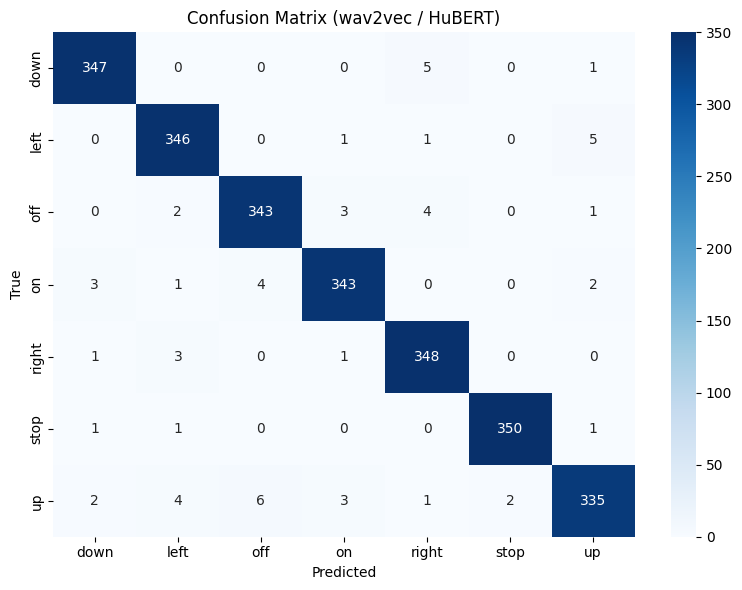

In [8]:
acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {acc:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASSES,
        zero_division=0,
        digits=4
    )
)

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (wav2vec / HuBERT)")
plt.tight_layout()
plt.show()